# 기상·지역 요인을 고려한 국내 미세먼지 농도 분석과 예측

KMA ASOS 기상자료와 PM10 부유분진 자료를 관측소 코드와 시각으로 결합한 뒤,
다음 시간 PM10을 예측합니다.

In [1]:
# 데이터 처리, 시각화, 회귀 모델 학습에 필요한 라이브러리를 불러옵니다.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 노트북이 실행되는 폴더를 기준으로 데이터와 그래프 경로를 지정합니다.
ROOT = Path('.')
DATA_DIR = ROOT / 'data'
IMAGE_DIR = ROOT / 'images'
IMAGE_DIR.mkdir(exist_ok=True)

## 1. 데이터 결합

2023년과 2024년 자료를 같은 관측소 코드와 시각 기준으로 결합합니다.

In [2]:
# 연도별 미세먼지와 기상 자료를 불러와 하나로 정리하는 함수입니다.
def load_year(year):
    # 해당 연도의 PM10 관측 파일에서 분석에 필요한 열만 읽습니다.
    pm = pd.read_csv(DATA_DIR / f'kma_pm10_hourly_{year}.csv', encoding='cp949', usecols=[0, 1, 2, 3])
    pm.columns = ['station_code', 'station_name', 'datetime', 'pm10']

    # 같은 연도의 ASOS 자료에서 분석에 필요한 기상 열만 읽습니다.
    wx = pd.read_csv(DATA_DIR / f'kma_asos_hourly_{year}.csv', encoding='cp949', usecols=[0, 1, 2, 3, 4, 5])
    wx.columns = ['station_code', 'station_name', 'datetime', 'precipitation', 'wind_speed', 'wind_direction']

    # 날짜와 관측값을 계산에 사용할 수 있는 형식으로 변환합니다.
    pm['datetime'] = pd.to_datetime(pm['datetime'], errors='coerce')
    wx['datetime'] = pd.to_datetime(wx['datetime'], errors='coerce')
    pm['pm10'] = pd.to_numeric(pm['pm10'], errors='coerce')

    # 기상 관측값도 숫자로 변환합니다. 변환할 수 없는 값은 결측치가 됩니다.
    for c in ['precipitation', 'wind_speed', 'wind_direction']:
        wx[c] = pd.to_numeric(wx[c], errors='coerce')

    # 관측소 코드와 관측 시각이 모두 같은 자료끼리 결합합니다.
    weather_columns = ['station_code', 'datetime', 'precipitation', 'wind_speed', 'wind_direction']
    df = pm.merge(wx[weather_columns], on=['station_code', 'datetime'], how='inner')

    # 날짜 또는 PM10이 없는 행을 제외하고 관측소별 시간순으로 정렬합니다.
    df = df.dropna(subset=['datetime', 'pm10'])
    df = df.sort_values(['station_code', 'datetime'])

    # 강수량 결측은 비가 오지 않은 것으로 보고 0으로 채웁니다.
    df['precipitation'] = df['precipitation'].fillna(0)

    # 풍속·풍향은 먼저 관측소별 중앙값으로 채우고,
    # 해당 관측소 값도 없으면 전체 자료의 중앙값을 사용합니다.
    for c in ['wind_speed','wind_direction']:
        station_median = df.groupby('station_code')[c].transform('median')
        df[c] = df[c].fillna(station_median)
        df[c] = df[c].fillna(df[c].median())

    # 직전 1시간 및 24시간의 PM10 농도를 과거 정보 변수로 만듭니다.
    df['lag1_pm10'] = df.groupby('station_code')['pm10'].shift(1)
    df['lag24_pm10'] = df.groupby('station_code')['pm10'].shift(24)

    # 현재 시각 정보가 섞이지 않도록 직전 24시간 평균을 계산합니다.
    df['rolling24_pm10'] = df.groupby('station_code')['pm10'].transform(
        lambda values: values.shift(1).rolling(24).mean()
    )

    # 시간·월·요일을 분리해 시간대 및 계절 패턴을 모델에 제공합니다.
    df['hour'] = df['datetime'].dt.hour
    df['month'] = df['datetime'].dt.month
    df['dayofweek'] = df['datetime'].dt.dayofweek

    # 정답값은 현재가 아니라 같은 관측소의 다음 시간 PM10으로 지정합니다.
    df['target_next_pm10'] = df.groupby('station_code')['pm10'].shift(-1)

    # 과거 입력값이나 다음 시간 정답이 없는 행은 학습에서 제외합니다.
    required_columns = ['lag1_pm10', 'lag24_pm10', 'rolling24_pm10', 'target_next_pm10']
    return df.dropna(subset=required_columns)

# 2023년은 학습용, 2024년은 연도 간 성능 평가용 자료로 불러옵니다.
train = load_year(2023)
test = load_year(2024)

# 전처리 결과를 행·열 개수로 확인합니다.
print('train:', train.shape, 'test:', test.shape)

train: (182697, 14) test: (179849, 14)


## 2. 모델링

2023년으로 학습하고 2024년으로 평가해 연도 간 일반화 성능을 확인합니다.

In [3]:
# 모델 학습에 사용할 입력 변수와 예측할 정답 변수를 지정합니다.
features = ['station_code','lag1_pm10','lag24_pm10','rolling24_pm10','precipitation','wind_speed','wind_direction','hour','month','dayofweek']
X_train = train[features]
y_train = train['target_next_pm10']
X_test = test[features]
y_test = test['target_next_pm10']

# 선형 모델과 트리 기반 모델의 예측 성능을 비교합니다.
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2, n_jobs=-1, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2, n_jobs=-1, random_state=42),
}
results = {}

# 각 모델을 학습하고 2024년 자료의 예측값과 평가 지표를 저장합니다.
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = {
        'RMSE': mean_squared_error(y_test, pred) ** 0.5,
        'MAE': mean_absolute_error(y_test, pred),
        'R2': r2_score(y_test, pred),
    }
pd.DataFrame(results).T

,RMSE,MAE,R2
Linear Regression,12.276794,7.583602,0.750110
Random Forest,12.062384,7.328669,0.758762
Extra Trees,11.971659,7.312194,0.762377


## 3. 성능 시각화

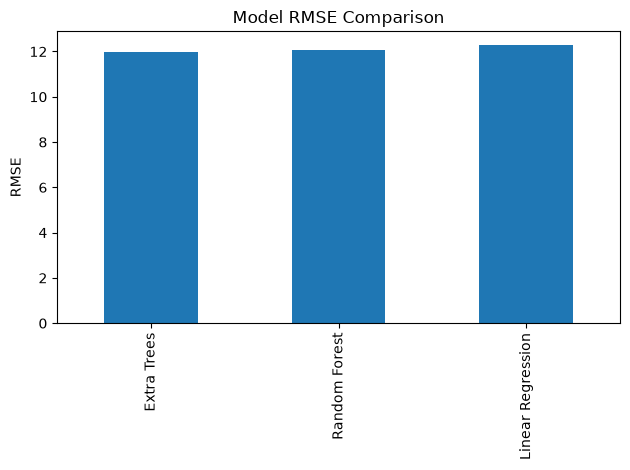

                        RMSE       MAE        R2
Extra Trees        11.971659  7.312194  0.762377
Random Forest      12.062384  7.328669  0.758762
Linear Regression  12.276794  7.583602  0.750110


In [4]:
# RMSE가 낮은 모델부터 정렬해 성능을 막대그래프로 비교합니다.
result_df = pd.DataFrame(results).T.sort_values('RMSE')
ax = result_df['RMSE'].plot(kind='bar', title='Model RMSE Comparison')
ax.set_ylabel('RMSE')
plt.tight_layout()
# 그래프를 README에서 사용할 수 있도록 이미지 파일로 저장합니다.
plt.savefig(IMAGE_DIR / 'model_comparison.png', dpi=150)
plt.show()
result_df

## 4. 특성 중요도

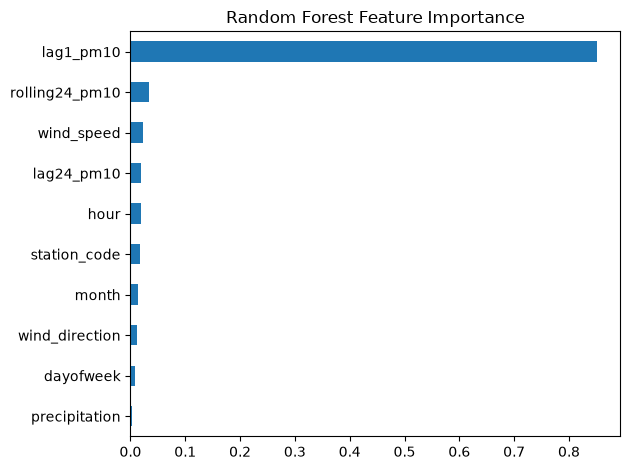

lag1_pm10         0.850565
rolling24_pm10    0.034105
wind_speed        0.022407
lag24_pm10        0.019977
hour              0.019539
station_code      0.016698
month             0.013031
wind_direction    0.011791
dayofweek         0.009018
precipitation     0.002869
dtype: float64


In [5]:
# Random Forest가 계산한 특성 중요도를 내림차순으로 정리합니다.
tree_model = models['Random Forest']
importance = pd.Series(tree_model.feature_importances_, index=features).sort_values(ascending=False)

# 중요도가 높은 상위 10개 변수를 가로 막대그래프로 나타냅니다.
ax = importance.head(10).plot(kind='barh', title='Random Forest Feature Importance')
ax.invert_yaxis()
plt.tight_layout()
# 특성 중요도 그래프도 이미지 파일로 저장합니다.
plt.savefig(IMAGE_DIR / 'feature_importance.png', dpi=150)
plt.show()
importance